In [ ]:
import sys; sys.path.insert(0, '../../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

from matplotlib.collections import LineCollection
from matplotlib import colors as mcolors
import scipy
import h5py

In [5]:
prefix = '/mnt/staging/'
figure_root = str(FIGURES / "figure5") + "/"

In [6]:
with h5py.File(figure_root+'histology_data_save.mat', "r") as h5f:
    # print(h5f.keys())
    dataset = np.array(h5f['data_save']).transpose((2,1,0))
    

In [7]:
print(dataset.shape)

(5207, 6578, 60)


In [8]:
y_axis_squeeze = np.max(dataset,axis=1)

In [9]:
y_axis_squeeze.shape

(5207, 60)

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:21: RuntimeWarning: divide by zero encountered in log


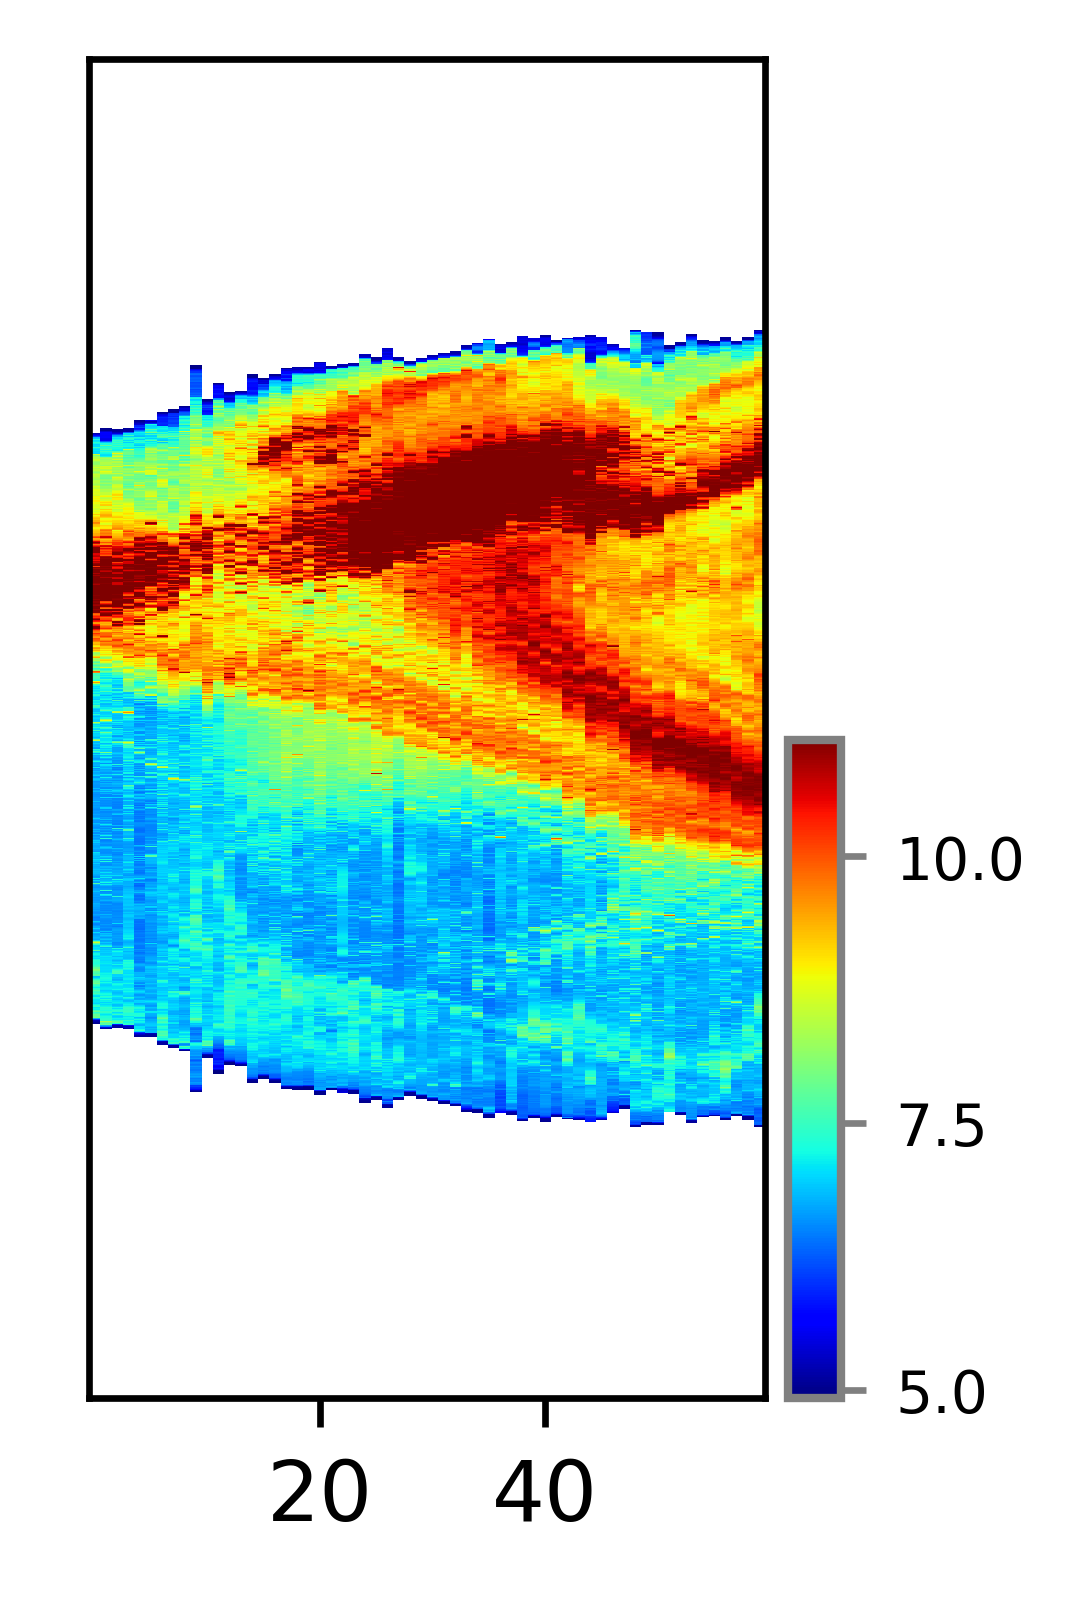

In [9]:
from matplotlib.gridspec import GridSpec
plt.style.use('default')
from matplotlib.ticker import FuncFormatter
from matplotlib import ticker
fmt = lambda x, pos: '{:.0%}'.format(x)

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=600)

y_offset = 20;x_offset=20;


ax0 = fig.add_subplot(gs[y_offset:y_offset+10,x_offset:x_offset+5])
ax990 = fig.add_subplot(gs[y_offset+5:y_offset+10,x_offset+5:x_offset+9])


# sbp0 = sns.heatmap(mean_intensity_projection.T,vmax=2000,vmin=0,cmap='gray',ax=ax0)

sbp0 = ax0.imshow(np.log(y_axis_squeeze),cmap='jet',aspect='auto',interpolation='nearest')


ax0.set_yticks([])
ax0.set_xticks([20,40])
        
# ax0.axhline(32)

cb = fig.colorbar(sbp0, cax=ax990,fraction=0.5,orientation='vertical');
cb.ax.tick_params(labelsize=7,length=3,color='gray')
cb.ax.yaxis.tick_right()       
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
ax990.set_aspect(2)
ax990.set_anchor('W')

plt.savefig('fig5-csn_MIP_side_view.svg',format='svg',dpi=300)


# mean intensity projection (dorsal view)

In [10]:
y_axis_squeeze.shape

(5207, 60)

In [11]:
dataset.shape

(5207, 6578, 60)

In [12]:
mask_dataset = dataset > 1000
mask_dataset = mask_dataset.astype('float')
mask_dataset[mask_dataset==False] = np.nan
masked_dataset = np.multiply(mask_dataset,dataset)

In [13]:
y_axis_squeeze_1 = np.nanmax(masked_dataset,axis=1)

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:1: RuntimeWarning: All-NaN slice encountered
  """Entry point for launching an IPython kernel.


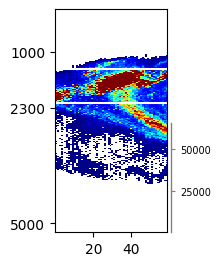

In [14]:
from matplotlib.gridspec import GridSpec
plt.style.use('default')
from matplotlib.ticker import FuncFormatter
from matplotlib import ticker
fmt = lambda x, pos: '{:.0%}'.format(x)

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=100)

y_offset = 20;x_offset=20;


ax0 = fig.add_subplot(gs[y_offset:y_offset+10,x_offset:x_offset+5])
ax990 = fig.add_subplot(gs[y_offset+5:y_offset+10,x_offset+5:x_offset+9])


# sbp0 = sns.heatmap(mean_intensity_projection.T,vmax=2000,vmin=0,cmap='gray',ax=ax0)

sbp0 = ax0.imshow(y_axis_squeeze_1,cmap='jet',aspect='auto',interpolation='nearest')


ax0.set_yticks([1000,2300,5000])
ax0.set_xticks([20,40])
        
# ax0.axhline(32)

cb = fig.colorbar(sbp0, cax=ax990,fraction=0.5,orientation='vertical');
cb.ax.tick_params(labelsize=7,length=3,color='gray')
cb.ax.yaxis.tick_right()       
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
ax990.set_aspect(2)
ax990.set_anchor('W')
ax0.axhline(1400,color='white')
ax0.axhline(2200,color='white')


In [15]:
z_axis_squeeze = np.mean(dataset[1400:2200,:,:],axis=0)

In [16]:
mask_dataset = np.log(np.max(dataset,axis=0)) > 0
mask_dataset = mask_dataset.astype('float')
mask_dataset[mask_dataset==0] = np.nan
mask_dataset = mask_dataset.T

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:1: RuntimeWarning: divide by zero encountered in log
  """Entry point for launching an IPython kernel.


In [17]:
dorsal_mean_intensity_projection = np.multiply(mask_dataset,z_axis_squeeze.T)

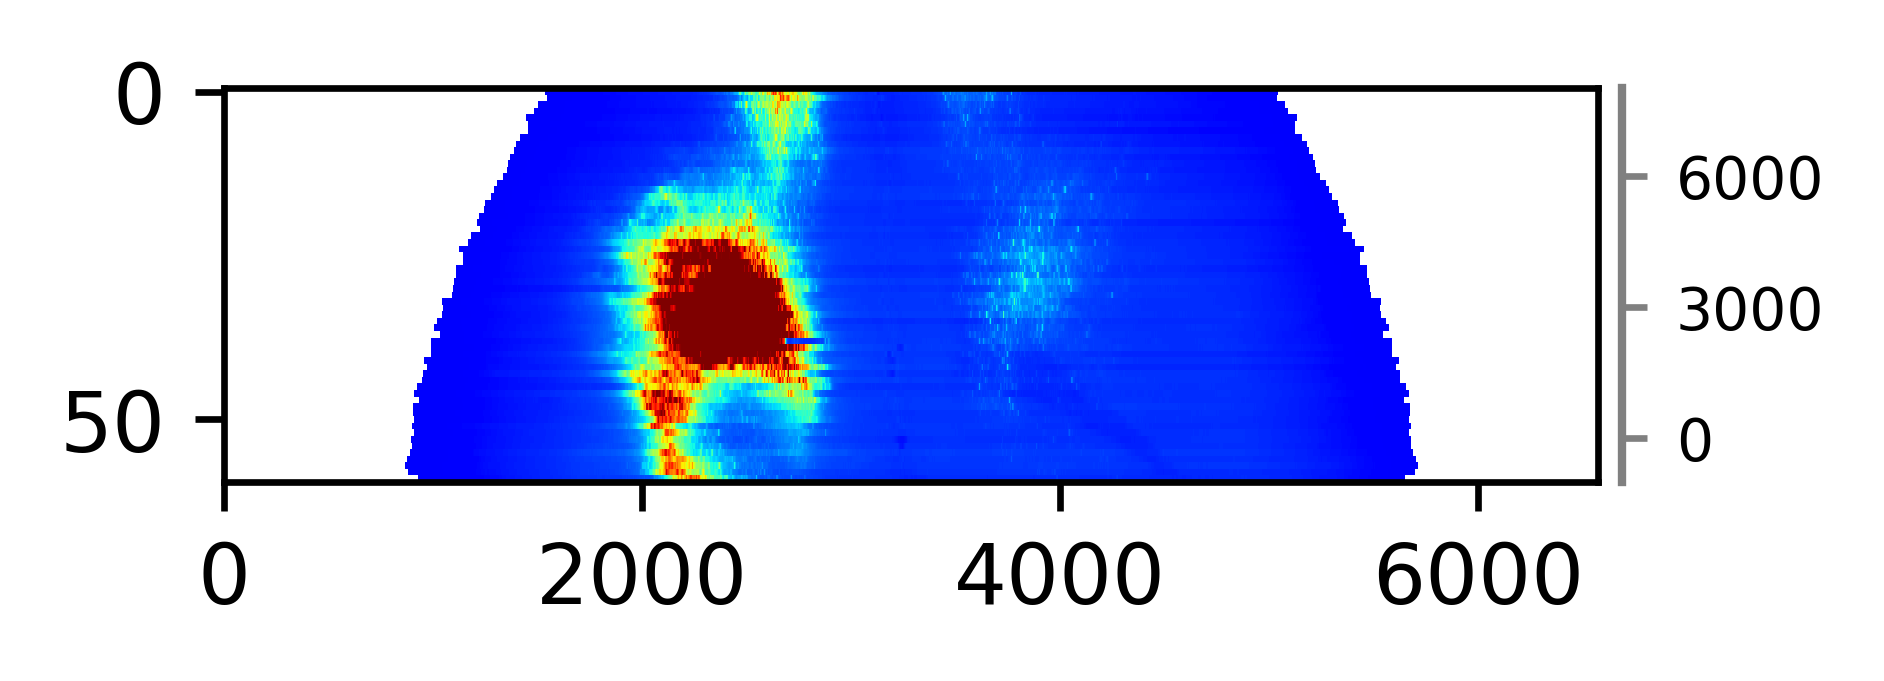

In [18]:
from matplotlib.gridspec import GridSpec
plt.style.use('default')
from matplotlib.ticker import FuncFormatter
from matplotlib import ticker
fmt = lambda x, pos: '{:.0%}'.format(x)

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=600)

y_offset = 20;x_offset=20;


ax0 = fig.add_subplot(gs[y_offset:y_offset+3,x_offset:x_offset+10])
ax990 = fig.add_subplot(gs[y_offset:y_offset+3,x_offset+10:x_offset+19])


# sbp0 = sns.heatmap(mean_intensity_projection.T,vmax=2000,vmin=0,cmap='gray',ax=ax0)

sbp0 = ax0.imshow(dorsal_mean_intensity_projection,cmap='jet',aspect='auto',vmin=-1000,vmax=8000,interpolation='nearest')


# ax0.set_yticks([])
# ax0.set_xticks([20,40])
        
# ax0.axhline(32)

cb = fig.colorbar(sbp0, cax=ax990,fraction=0.5,orientation='vertical');
cb.ax.tick_params(labelsize=7,length=3,color='gray')
cb.ax.yaxis.tick_right()       
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
ax990.set_aspect(2)
ax990.set_anchor('W')

# plt.savefig('fig5-csn_meanIP_side_view.svg',format='svg',dpi=300)


# overlay Allen

config

In [6]:
figure_config_root = str(PREPARES / "config") + "/"
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#cd80a1'
palatte_dict['tail'] = 'palegreen'
palatte_dict['LT'] = '#b3b3b3'
palatte_dict['RT']  = '#e4c494' ##b69d76 back up
palatte_dict['RT']  = '#b69d76' # back up

dict_color_matching = {
'SSp_tr':palatte_dict['RT'],'SSp_n':palatte_dict['RN'],
'SSp_bfd':palatte_dict['RW'],'SSp_ll':palatte_dict['RHP'],'SSp_m':palatte_dict['RM'],
'VIS':palatte_dict['RV'],'RSP':palatte_dict['RSP'],'SSp_ul':palatte_dict['RFP'],
    # 'MOp':'#ADD8E6','MOs':'#74ca6a'   
    'MOp':'lightgray','MOs':'darkgray'  ,'SSs':'darkslategray'
}


In [7]:
palatte_dict

{'RFP': '#015EB5',
 'LFP': '#ABC9E3',
 'RM': '#df2f2b',
 'LM': '#ee8c7d',
 'RW': '#501d8a',
 'LW': '#bf8fc9',
 'RHP': '#efb708',
 'LHP': '#e6ff05',
 'RN': '#1c8041',
 'LN': '#B0D8AA',
 'RV': '#B01A5B',
 'LV': '#cd80a1',
 'ALM': '#936F65',
 'RSP': '#C65541',
 'RM_M2': '#bf8fc9',
 'RM_M1': 'lightseagreen',
 'RFP_M2': '#6dae96',
 'RFP_M1': '#4fa7c5',
 'RM_S1': '#df2f2b',
 'RFP_S1': '#015EB5',
 'mouth': '#df2f2b',
 'nose': '#1c8041',
 'tail': 'palegreen',
 'LT': '#b3b3b3',
 'RT': '#b69d76'}

In [8]:
dict_color_matching

{'SSp_tr': '#b69d76',
 'SSp_n': '#1c8041',
 'SSp_bfd': '#501d8a',
 'SSp_ll': '#efb708',
 'SSp_m': '#df2f2b',
 'VIS': '#B01A5B',
 'RSP': '#C65541',
 'SSp_ul': '#015EB5',
 'MOp': 'lightgray',
 'MOs': 'darkgray',
 'SSs': 'darkslategray'}

In [20]:
figure_config_root = str(PREPARES / "config") + "/"
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#cd80a1'
palatte_dict['tail'] = 'palegreen'
palatte_dict['LT'] = '#b3b3b3'
palatte_dict['RT']  = '#e4c494' ##b69d76 back up
palatte_dict['RT']  = '#b69d76' # back up

dict_color_matching = {
'SSp_tr':palatte_dict['RT'],'SSp_n':palatte_dict['RN'],
'SSp_bfd':palatte_dict['RW'],'SSp_ll':palatte_dict['RHP'],'SSp_m':palatte_dict['RM'],
'VIS':palatte_dict['RV'],'RSP':palatte_dict['RSP'],'SSp_ul':palatte_dict['RFP'],
    # 'MOp':'#ADD8E6','MOs':'#74ca6a'   
    'MOp':'lightgray','MOs':'darkgray'  ,'SSs':'darkslategray'
}

ABA_data_root =  str(FIGURES / "figure5") + "/"
atlas = scipy.io.loadmat(ABA_data_root+'atlas.mat')['atlas']
areanames = scipy.io.loadmat(ABA_data_root+'atlas.mat')['areanames']

atlas[atlas==0]=np.nan
atlas[atlas==-301]=np.nan # remove OLB
atlas[atlas==301]=np.nan # remove OLB

areas = np.unique(atlas).astype('int')
areas = areas[areas>-1000]

def parse_areanames(areanames_):
    areainds=[]; areanames=[];
    for i,area in enumerate(areanames_[0][0]):
        areainds.append(area[0][0])
        areanames.append(areanames_[0][0].dtype.descr[i][0])
    sortvec=np.argsort(np.abs(areainds))
    areanames=[areanames[i] for i in sortvec]
    areainds=[areainds[i] for i in sortvec]
    return areainds,areanames

# Get area names for all components
areainds,areanames_all = parse_areanames(areanames)
areanames_area=[]
areainds_area=[]
dict_ind_area = {}
for i,area in enumerate(areas):
    areanames_area.append(areanames_all[areainds.index(area)])
    areainds_area.append(areainds.index(area))
    dict_ind_area[areanames_all[areainds.index(area)]] = area
    

color_dict = {}
# Fixing random seed for consistent colors
np.random.seed(42)
for name in areanames_area:
    color_assigned = False
    for key in dict_color_matching:
        if key in name:
            color_dict[name] = dict_color_matching[key]
            color_assigned = True
            break
    if not color_assigned:
        # Generate a random color in hexadecimal format
        # random_color = "#{:06x}".format(random.randint(0, 0xFFFFFF))
        color_dict[name] = 'black'#random_color

# (137,130) #bregma location
pixels_per_mm = 50.79
x_axis = np.divide(np.linspace(-270,540-270-1,540),pixels_per_mm)
y_axis = np.divide(np.linspace(540-270-1,-270,540),pixels_per_mm)
extent_allen = [x_axis[0],x_axis[-1],y_axis[-1],y_axis[0]]


In [21]:
simplified_color_dict = {}
for key, color in color_dict.items():
    if color not in simplified_color_dict:
        simplified_color_dict[color] = []
    simplified_color_dict[color].append(key)

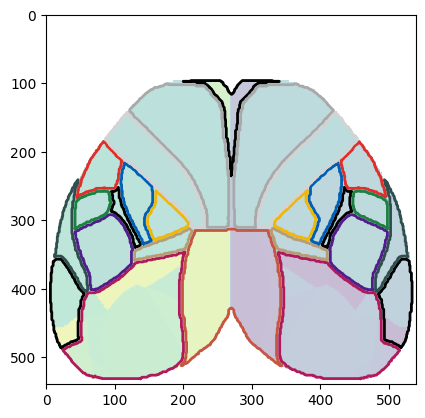

In [22]:
from skimage import measure
from skimage.morphology import binary_erosion, disk
structuring_element = disk(2)
# plt.figure(dpi=300)
plt.imshow(atlas,alpha=0.3)
for color_here in simplified_color_dict:
    map_here_added = np.zeros((540,540))
    for areaname in simplified_color_dict[color_here]:
        ind_area = dict_ind_area[areaname]

        map_here = atlas==ind_area
        map_here = map_here.astype('float')
        map_here_added += map_here
        # map_here[map_here==0]=np.nan
    
    filled_bw = scipy.ndimage.morphology.binary_fill_holes(map_here_added>0.2)
    filled_bw = binary_erosion(filled_bw, structuring_element)
    contours = measure.find_contours(filled_bw, 0.8)

    # plt.imshow(map_here,cmap=cmap_rb)
    for contour in contours:
        if len(contour)>50:
            plt.plot(contour[:,1],contour[:,0],linewidth=2,color=color_here)
        
    
# print(plt.gca().get_ylim())
# print(plt.gca().get_xlim())



In [145]:
resized_image_MIP = cv2.resize(dorsal_mean_intensity_projection[:,650:-650],
                               (580, 186), interpolation=cv2.INTER_LINEAR)

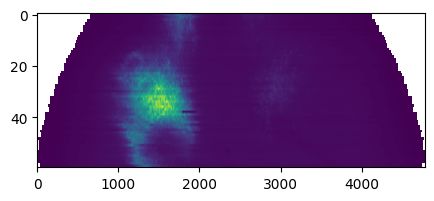

In [146]:
plt.figure(figsize=(5,2))
plt.imshow(dorsal_mean_intensity_projection[:,900:-900],aspect='auto')

In [148]:
ss = resized_image_MIP.shape
print(ss)

(186, 580)


In [152]:
temp_img = np.zeros_like(map_here_added)
temp_img[:]=np.nan
slice_start = 140
temp_img[slice_start:slice_start+ss[0],:] = resized_image_MIP[:,20:-20]
slice_cut = slice_start + (375-160)*(32/60)

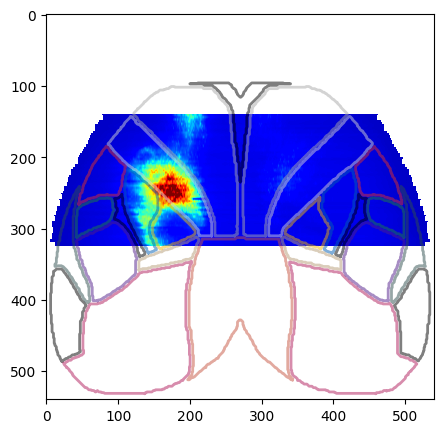

In [154]:
from skimage import measure
from skimage.morphology import binary_erosion, disk
structuring_element = disk(2)
plt.figure(figsize=(5,5))
plt.imshow(temp_img,cmap='jet',aspect='auto',vmin=-1000,vmax=15000)
dict_contours = {}
for color_here in simplified_color_dict:
    map_here_added = np.zeros((540,540))
    for areaname in simplified_color_dict[color_here]:
        ind_area = dict_ind_area[areaname]

        map_here = atlas==ind_area
        map_here = map_here.astype('float')
        map_here_added += map_here
        # map_here[map_here==0]=np.nan
    
    filled_bw = scipy.ndimage.morphology.binary_fill_holes(map_here_added>0.2)
    filled_bw = binary_erosion(filled_bw, structuring_element)
    contours = measure.find_contours(filled_bw, 0.8)

    # plt.imshow(map_here,cmap=cmap_rb)
    for contour in contours:
        if len(contour)>50:
            plt.plot(contour[:,1],contour[:,0],linewidth=2,color=color_here,alpha=0.5)
        
    dict_contours[color_here]=contours
# print(plt.gca().get_ylim())
# print(plt.gca().get_xlim())




In [155]:
temp_img.shape

(540, 540)

# save a figure

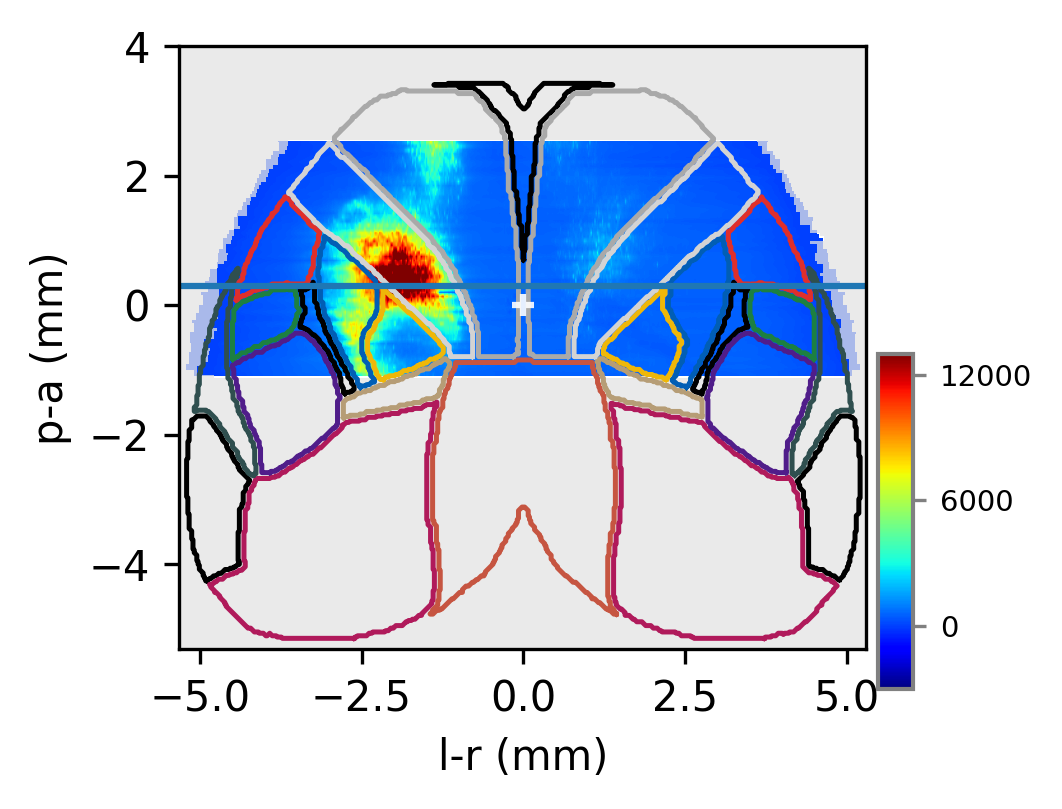

In [157]:
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)



y_offset = 20;x_offset=20;
x_width=10;

x_start = x_offset
x_stop = x_start+x_width
ax0 = fig.add_subplot(gs[y_offset:y_offset+10,x_start:x_stop])
ax990 = fig.add_subplot(gs[y_offset+5:y_offset+10,x_stop:x_stop+2])

#======
sbp0 = ax0.imshow(temp_img,cmap='jet',aspect='auto',vmin=-3000,vmax=13000,extent=extent_allen)
for color_here in simplified_color_dict:
    contours = dict_contours[color_here]
    for contour in contours:
        if len(contour)>50:
            ax0.plot((contour[:,1]-270)/pixels_per_mm,(540-contour[:,0]-270)/pixels_per_mm,linewidth=1.2,alpha=1,
                         # linestyle='dashed'
                     color=color_here)

ax0.set_ylim([-5.31,4])

c_black= matplotlib.colors.colorConverter.to_rgba('#e3e3e3',alpha = 1)
c_black1= matplotlib.colors.colorConverter.to_rgba('#e3e3e3',alpha = 0.75)
c_white= matplotlib.colors.colorConverter.to_rgba('#e3e3e3',alpha = 0.75)
cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black1,c_black],5120)
map_here = np.nan_to_num(temp_img.copy(),0)==0
map_here = map_here.astype('float')
map_here[map_here==0]=np.nan
ax0.imshow(map_here,cmap=cmap_rb,extent=extent_allen)

ax0.scatter(0,0,s=30,marker='+',color='white',alpha=0.9,zorder=9999) #bregma location

ax0.axhline(y_axis[int(slice_cut)])
ax0.set_xlabel('l-r (mm)')
ax0.set_ylabel('p-a (mm)')


cb = fig.colorbar(sbp0, cax=ax990,fraction=0.5,orientation='vertical');
cb.ax.tick_params(labelsize=7,length=3,color='gray')
cb.ax.yaxis.tick_right()       
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
ax990.set_aspect(0.0006)
ax990.set_anchor('W')



plt.savefig('fig5-Allen-CSN-meanIP.svg',format='svg',dpi=300)